In [3]:
%pip install --default-timeout=300 --retries 15 --no-cache-dir "transformers<5" datasets sentencepiece rouge-score accelerate scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
#IMPORT DAN PARAMETER

In [5]:
!pip install --upgrade protobuf sentencepiece

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached sentencepiece-0.2.3-cp312-cp312-win_amd64.whl.metadata (35 kB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Using cached sentencepiece-0.2.3-cp312-cp312-win_amd64.whl (1.7 MB)
  Attempting uninstall: sentencepiece
    Found existing installation: sentencepiece 0.2.2
    Uninstalling sentencepiece-0.2.2:
      Successfully uninstalled sentencepiece-0.2.2
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled protobuf-5.29.5


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.1.1 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [6]:
pip install hf_xet

Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install "sentencepiece==0.2.2"

  Using cached sentencepiece-0.2.2-cp312-cp312-win_amd64.whl.metadata (34 kB)
Using cached sentencepiece-0.2.2-cp312-cp312-win_amd64.whl (1.2 MB)
  Attempting uninstall: sentencepiece
    Found existing installation: sentencepiece 0.2.3
    Uninstalling sentencepiece-0.2.3:
      Successfully uninstalled sentencepiece-0.2.3
Note: you may need to restart the kernel to use updated packages.


In [8]:
%pip install --force-reinstall protobuf==5.29.5

  Using cached protobuf-5.29.5-cp310-abi3-win_amd64.whl.metadata (592 bytes)
Using cached protobuf-5.29.5-cp310-abi3-win_amd64.whl (434 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.36.2
    Uninstalling protobuf-7.36.2:
      Successfully uninstalled protobuf-7.36.2
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.1.1 which is incompatible.


In [9]:
import google.protobuf
import sentencepiece
import transformers
import pandas
import torch

print("Protobuf:", google.protobuf.__version__)
print("SentencePiece:", sentencepiece.__version__)
print("Transformers:", transformers.__version__)
print("Pandas:", pandas.__version__)
print("Torch:", torch.__version__)

Protobuf: 5.29.5
SentencePiece: 0.2.2
Transformers: 4.57.6
Pandas: 3.1.1
Torch: 2.15.0+cpu


In [10]:
import re
import math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from rouge_score import rouge_scorer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_NAME = "panggi/t5-small-indonesian-summarization-cased"
DATASET_NAME = "joshuasiagian/indosum"

SAMPLE_INDEX = 0
MAX_INPUT_LENGTH = 512
MAX_NEW_TOKENS = 128

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cpu


In [11]:
dataset = load_dataset(DATASET_NAME)

print(dataset)
print("\nKolom:", dataset["test"].column_names)
print("Jumlah data test:", len(dataset["test"]))


DatasetDict({
    train: Dataset({
        features: ['paragraph', 'summary'],
        num_rows: 14262
    })
    validation: Dataset({
        features: ['paragraph', 'summary'],
        num_rows: 750
    })
    test: Dataset({
        features: ['paragraph', 'summary'],
        num_rows: 3762
    })
})

Kolom: ['paragraph', 'summary']
Jumlah data test: 3762


In [12]:
sample = dataset["test"][SAMPLE_INDEX]

artikel = sample["paragraph"].strip()
gold_summary = sample["summary"].strip()

print("PANJANG ARTIKEL:", len(artikel.split()), "kata")
print("PANJANG GOLD SUMMARY:", len(gold_summary.split()), "kata")

print("\n===== ARTIKEL =====\n")
print(artikel)

print("\n===== GOLD SUMMARY =====\n")
print(gold_summary)


PANJANG ARTIKEL: 387 kata
PANJANG GOLD SUMMARY: 59 kata

===== ARTIKEL =====

Jakarta, CNN Indonesia - - Dilansir AFP, seorang warga Mesir yang dipercaya sebagai wanita terberat di dunia masuk sebuah rumah sakit di Abu Dhabi Kamis (5 / 5), dimana ia akan melanjutkan perawatan setelah menjalankan operasi menurunkan badan di India. Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan operasi di Mumbai Maret lalu dimana ia mengurangi seperlima dari berat badannya. Ia menderita berbagai macam masalah kesehatan termasuk penyakit gajah, kondisi yang menyebabkan anggota badan membengkak. Abd El Aty diberi diet cairan khusus selama berada di India yang bertujuan menurunkan berat badan. Diet ini memungkinkan dokter melakukan operasi bariatrik, prosedur bypass yang kini sering dilakukan di India dalam menghadapi masalah obesitas yang bertambah banyak. Ia tiba di India dengan menggunakan pesawat Airbus yang secara khusus telah dimodifikasi khusus untuk mengangkutny

In [13]:
#MEMUAT MODEL T5 ABSTRACTIVE SUMMARIZATION

In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
model = model.to(device)
model.eval()

print("Model:", MODEL_NAME)
print("Jumlah parameter:", f"{sum(p.numel() for p in model.parameters()):,}")


You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Model: panggi/t5-small-indonesian-summarization-cased
Jumlah parameter: 60,506,624


In [15]:
#TOKENISASI ARTIKEL

In [16]:
input_text = "summarize: " + artikel

tokens_full = tokenizer(
    input_text,
    return_tensors="pt",
    truncation=False
)

jumlah_token_asli = tokens_full["input_ids"].shape[1]

inputs = tokenizer(
    input_text,
    return_tensors="pt",
    max_length=MAX_INPUT_LENGTH,
    truncation=True
)

jumlah_token_dipakai = inputs["input_ids"].shape[1]

print("Token sebelum truncation:", jumlah_token_asli)
print("Token yang masuk model:", jumlah_token_dipakai)
print("Terpotong?", jumlah_token_asli > jumlah_token_dipakai)


Token sebelum truncation: 501
Token yang masuk model: 501
Terpotong? False


In [17]:
#GENERATE RINGKASAN ABSTRACTIVE

In [18]:
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        num_beams=4,
        do_sample=False,
        no_repeat_ngram_size=3,
        repetition_penalty=1.2,
        length_penalty=1.0,
        early_stopping=True
    )

generated_summary = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
).strip()

print("===== RINGKASAN T5 =====\n")
print(generated_summary)


===== RINGKASAN T5 =====

Seorang warga Mesir yang dipercaya sebagai wanita terberat di dunia masuk sebuah rumah sakit di Abu Dhabi Kamis ( 5 / 5 ), dimana ia akan melanjutkan perawatan setelah menjalankan operasi menurunkan badan di India. Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan operasi di Mumbai Maret lalu dimana ia mengurangi seperlima dari berat badannya. Ia menderita berbagai macam masalah kesehatan termasuk penyakit gajah, kondisi yang menyebabkan anggota badan membengkak.


In [19]:
print(model.generation_config)

GenerationConfig {
  "decoder_start_token_id": 0,
  "eos_token_id": 1,
  "pad_token_id": 0
}



In [20]:
# BAGIAN 6

In [21]:
def pecah_kalimat(teks):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+', teks) if s.strip()]

generated_sentences = pecah_kalimat(generated_summary)

abstractive_check = []
for i, s in enumerate(generated_sentences, start=1):
    exact = s.lower() in artikel.lower()
    abstractive_check.append({
        "Kalimat ringkasan": f"G{i}",
        "Teks": s,
        "Muncul persis dalam artikel?": "Ya" if exact else "Tidak"
    })

pd.DataFrame(abstractive_check)


,Kalimat ringkasan,Teks,Muncul persis dalam artikel?
0,G1,Seorang warga Mesir yang dipercaya sebagai wan...,Tidak
1,G2,Eman Ahmed Abd El Aty memiliki berat badan men...,Ya
2,G3,Ia menderita berbagai macam masalah kesehatan ...,Ya


In [22]:
#BAGIAN ROUGE

In [23]:
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=False
)

scores = scorer.score(gold_summary, generated_summary)

rouge_table = pd.DataFrame([
    {
        "Metric": metric,
        "Precision": value.precision,
        "Recall": value.recall,
        "F1": value.fmeasure
    }
    for metric, value in scores.items()
])

rouge_table.round(4)


,Metric,Precision,Recall,F1
0,rouge1,0.4167,0.5000,0.4545
1,rouge2,0.3521,0.4237,0.3846
2,rougeL,0.3750,0.4500,0.4091


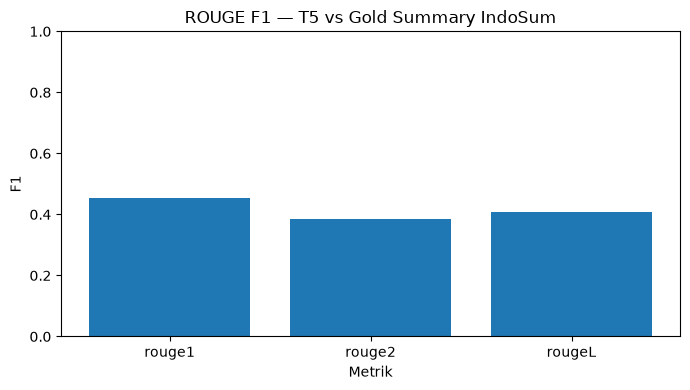

In [24]:
plt.figure(figsize=(7,4))
plt.bar(rouge_table["Metric"], rouge_table["F1"])
plt.ylim(0,1)
plt.ylabel("F1")
plt.xlabel("Metrik")
plt.title("ROUGE F1 — T5 vs Gold Summary IndoSum")
plt.tight_layout()
plt.show()


In [25]:
#FACTUALITY AUDIT OTOMMATIS SEDERHANA

In [26]:
def ekstrak_angka(teks):
    pola = r'\b\d+(?:[.,]\d+)?(?:%| persen)?\b'
    return re.findall(pola, teks.lower())

angka_artikel = set(ekstrak_angka(artikel))
angka_gold = set(ekstrak_angka(gold_summary))
angka_model = set(ekstrak_angka(generated_summary))

audit_angka = pd.DataFrame({
    "Sumber": ["Artikel", "Gold summary", "Ringkasan T5"],
    "Angka": [
        sorted(angka_artikel),
        sorted(angka_gold),
        sorted(angka_model)
    ]
})

display(audit_angka)

angka_tidak_didukung = angka_model - angka_artikel
print("\nAngka model yang tidak ditemukan di artikel:", sorted(angka_tidak_didukung))


,Sumber,Angka
0,Artikel,"[176,6, 293, 323, 5, 500]"
1,Gold summary,"[176,6, 323, 500]"
2,Ringkasan T5,"[5, 500]"



Angka model yang tidak ditemukan di artikel: []


In [27]:
#BAGIAN 10

In [28]:
kalimat_sumber = pecah_kalimat(artikel)

vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w\w+\b"
)

X = vectorizer.fit_transform(kalimat_sumber)
similarity = cosine_similarity(X)
np.fill_diagonal(similarity, 0.0)

row_sum = similarity.sum(axis=1)
P = np.zeros_like(similarity)

for i in range(len(kalimat_sumber)):
    if row_sum[i] > 0:
        P[i] = similarity[i] / row_sum[i]

d = 0.85
tr = np.ones(len(kalimat_sumber))

for _ in range(100):
    tr_new = (1-d) + d * P.T.dot(tr)
    if np.max(np.abs(tr_new-tr)) < 1e-8:
        tr = tr_new
        break
    tr = tr_new

# pilih jumlah kalimat kira-kira sesuai panjang gold summary
rata_kata_per_kalimat = np.mean([len(s.split()) for s in kalimat_sumber])
n_extract = max(1, round(len(gold_summary.split()) / rata_kata_per_kalimat))

top_idx = np.argsort(tr)[::-1][:n_extract]
top_idx = sorted(top_idx)

textrank_summary = " ".join(kalimat_sumber[i] for i in top_idx)

print("Jumlah kalimat source:", len(kalimat_sumber))
print("Kalimat yang dipilih:", [i+1 for i in top_idx])
print("\n===== RINGKASAN TEXTRANK =====\n")
print(textrank_summary)


Jumlah kalimat source: 18
Kalimat yang dipilih: [np.int64(2), np.int64(4), np.int64(18)]

===== RINGKASAN TEXTRANK =====

Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan operasi di Mumbai Maret lalu dimana ia mengurangi seperlima dari berat badannya. Abd El Aty diberi diet cairan khusus selama berada di India yang bertujuan menurunkan berat badan. Juli tahun lalu, Guinness Book of World Records mencatat warga AS Pauline Potter sebagai wanita terberat dengan berat badan 293 kilogram, jauh di atas berat badan Abd El Aty yang sekarang.


In [29]:
#BAGIAN 11

In [30]:
def hitung_rouge(reference, prediction):
    s = scorer.score(reference, prediction)
    return {
        "ROUGE-1 F1": s["rouge1"].fmeasure,
        "ROUGE-2 F1": s["rouge2"].fmeasure,
        "ROUGE-L F1": s["rougeL"].fmeasure
    }

comparison = pd.DataFrame([
    {"Model": "TextRank", **hitung_rouge(gold_summary, textrank_summary)},
    {"Model": "T5 Abstractive", **hitung_rouge(gold_summary, generated_summary)}
])

comparison.round(4)


,Model,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1
0,TextRank,0.6818,0.6154,0.6667
1,T5 Abstractive,0.4545,0.3846,0.4091


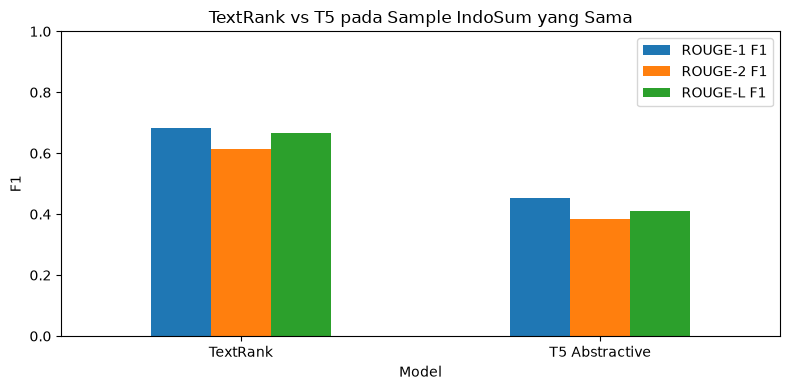

In [31]:
comparison_plot = comparison.set_index("Model")
comparison_plot.plot(kind="bar", figsize=(8,4))
plt.ylim(0,1)
plt.ylabel("F1")
plt.title("TextRank vs T5 pada Sample IndoSum yang Sama")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:
#BAGIAN 12

In [33]:
def generate_t5(article):
    text = "summarize: " + article
    enc = tokenizer(
        text,
        return_tensors="pt",
        max_length=MAX_INPUT_LENGTH,
        truncation=True
    )
    enc = {k: v.to(device) for k, v in enc.items()}

    with torch.no_grad():
        ids = model.generate(
            **enc,
            max_new_tokens=MAX_NEW_TOKENS,
            num_beams=4,
            do_sample=False,
            no_repeat_ngram_size=3,
            repetition_penalty=1.2,
            early_stopping=True
        )
    return tokenizer.decode(ids[0], skip_special_tokens=True).strip()

hasil_lima = []

for idx in range(5):
    item = dataset["test"][idx]
    pred = generate_t5(item["paragraph"])
    rg = hitung_rouge(item["summary"], pred)

    hasil_lima.append({
        "Index": idx,
        "Article words": len(item["paragraph"].split()),
        "Gold words": len(item["summary"].split()),
        "Generated words": len(pred.split()),
        **rg
    })

hasil_lima_df = pd.DataFrame(hasil_lima)
hasil_lima_df.round(4)


,Index,Article words,Gold words,Generated words,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1
0,0,387,59,75,0.4545,0.3846,0.4091
1,1,193,66,53,0.5345,0.4737,0.5172
2,2,316,57,69,0.7302,0.6129,0.3810
3,3,242,62,44,0.7255,0.7200,0.7255
4,4,406,52,54,0.6916,0.6476,0.6542


In [34]:
print("Rata-rata 5 sample:")
display(
    hasil_lima_df[
        ["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]
    ].mean().to_frame("Mean").round(4)
)


Rata-rata 5 sample:


,Mean
ROUGE-1 F1,0.6273
ROUGE-2 F1,0.5678
ROUGE-L F1,0.5374


In [35]:
#PERCOBAAN
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        num_beams=1,
        do_sample=False,
        no_repeat_ngram_size=3,
        repetition_penalty=1.2
        
    )

generated_summary_beam1 = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
).strip()

print("===== RINGKASAN T5 (num_beams=1) =====\n")
print(generated_summary_beam1)
print("Jumlah kata:", len(generated_summary_beam1.split()))

===== RINGKASAN T5 (num_beams=1) =====

Seorang warga Mesir yang dipercaya sebagai wanita terberat di dunia masuk sebuah rumah sakit di Abu Dhabi Kamis ( 5 / 5 ), dimana ia akan melanjutkan perawatan setelah menjalankan operasi menurunkan badan di India. Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan operasi di Mumbai Maret lalu dimana ia mengurangi seperlima dari berat badannya. Ia menderita berbagai macam masalah kesehatan termasuk penyakit gajah, kondisi yang menyebabkan anggota badan membengkak.
Jumlah kata: 75


In [36]:
def pecah_kalimat(teks):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+', teks) if s.strip()]

generated_sentences = pecah_kalimat(generated_summary_beam1)

abstractive_check = []
for i, s in enumerate(generated_sentences, start=1):
    exact = s.lower() in artikel.lower()
    abstractive_check.append({
        "Kalimat ringkasan": f"G{i}",
        "Teks": s,
        "Muncul persis dalam artikel?": "Ya" if exact else "Tidak"
    })

pd.DataFrame(abstractive_check)

,Kalimat ringkasan,Teks,Muncul persis dalam artikel?
0,G1,Seorang warga Mesir yang dipercaya sebagai wan...,Tidak
1,G2,Eman Ahmed Abd El Aty memiliki berat badan men...,Ya
2,G3,Ia menderita berbagai macam masalah kesehatan ...,Ya


In [37]:
#ROUGE
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=False
)

scores = scorer.score(gold_summary,generated_summary_beam1)

rouge_table = pd.DataFrame([
    {
        "Metric": metric,
        "Precision": value.precision,
        "Recall": value.recall,
        "F1": value.fmeasure
    }
    for metric, value in scores.items()
])

rouge_table.round(4)


,Metric,Precision,Recall,F1
0,rouge1,0.4167,0.5000,0.4545
1,rouge2,0.3521,0.4237,0.3846
2,rougeL,0.3750,0.4500,0.4091


In [38]:
#FACTUALITY
def ekstrak_angka(teks):
    pola = r'\b\d+(?:[.,]\d+)?(?:%| persen)?\b'
    return re.findall(pola, teks.lower())

angka_artikel = set(ekstrak_angka(artikel))
angka_gold = set(ekstrak_angka(gold_summary))
angka_model = set(ekstrak_angka(generated_summary_beam1))

audit_angka = pd.DataFrame({
    "Sumber": ["Artikel", "Gold summary", "Ringkasan T5"],
    "Angka": [
        sorted(angka_artikel),
        sorted(angka_gold),
        sorted(angka_model)
    ]
})

display(audit_angka)

angka_tidak_didukung = angka_model - angka_artikel
print("\nAngka model yang tidak ditemukan di artikel:", sorted(angka_tidak_didukung))


,Sumber,Angka
0,Artikel,"[176,6, 293, 323, 5, 500]"
1,Gold summary,"[176,6, 323, 500]"
2,Ringkasan T5,"[5, 500]"



Angka model yang tidak ditemukan di artikel: []


In [161]:
# C. UJI TRUNCATION 

TARGET = 600 

# 1. Hitung token semua artikel test, simpan yang > 512
panjang_list = []
for idx in range(len(dataset["test"])):
    teks = "summarize: " + dataset["test"][idx]["paragraph"].strip()
    n = len(tokenizer(teks, truncation=False)["input_ids"])
    if n > MAX_INPUT_LENGTH:
        panjang_list.append((idx, n))

# 2. Urutkan berdasarkan kedekatan dengan TARGET
panjang_list.sort(key=lambda x: abs(x[1] - TARGET))
print("Jumlah artikel > 512 token:", len(panjang_list))
print("5 artikel terdekat dengan", TARGET, "token (index, token):", panjang_list[:5])

# Pilih urutan ke-0 = paling dekat dengan TARGET (ganti 0 jadi 1, 2, ... untuk artikel lain)
idx_panjang = panjang_list[0][0]
print("\nIndex artikel yang dipakai:", idx_panjang)

item = dataset["test"][idx_panjang]
artikel_p = item["paragraph"].strip()
gold_p = item["summary"].strip()

# 3. Bandingkan panjang artikel vs bagian yang masuk model
full_ids = tokenizer("summarize: " + artikel_p, truncation=False)["input_ids"]
masuk_ids = full_ids[:MAX_INPUT_LENGTH]
terpotong_ids = full_ids[MAX_INPUT_LENGTH:]

bagian_masuk = tokenizer.decode(masuk_ids, skip_special_tokens=True)
bagian_terpotong = tokenizer.decode(terpotong_ids, skip_special_tokens=True)

print("Panjang artikel  :", len(artikel_p.split()), "kata /", len(full_ids), "token")
print("Masuk ke model   :", len(masuk_ids), "token")
print("Terpotong        :", len(terpotong_ids), "token")

print("\n===== BAGIAN YANG TERPOTONG (setelah token ke-512) =====\n")
print(bagian_terpotong)

# 4. Fakta penting yang hanya ada di bagian terpotong
angka_masuk = set(ekstrak_angka(bagian_masuk))
angka_potong = set(ekstrak_angka(bagian_terpotong))
print("\nAngka hanya di bagian terpotong:", sorted(angka_potong - angka_masuk))

kata_masuk = set(bagian_masuk.lower().split())
kata_potong = set(bagian_terpotong.lower().split())
kata_gold = set(gold_p.lower().split())
print("Kata gold summary yang hanya ada di bagian terpotong:",
      sorted((kata_gold & kata_potong) - kata_masuk))

# 5. Ringkasan T5, gold summary, dan ROUGE
pred_p = generate_t5(artikel_p)
print("\n===== RINGKASAN T5 =====\n", pred_p)
print("\n===== GOLD SUMMARY =====\n", gold_p)
print("\nAngka di gold summary:", sorted(ekstrak_angka(gold_p)))
print("Angka di ringkasan T5:", sorted(ekstrak_angka(pred_p)))
print("\nROUGE F1:", {k: round(v, 4) for k, v in hitung_rouge(gold_p, pred_p).items()})

Jumlah artikel > 512 token: 906
5 artikel terdekat dengan 600 token (index, token): [(1652, 600), (3469, 600), (516, 601), (568, 599), (1941, 601)]

Index artikel yang dipakai: 1652
Panjang artikel  : 450 kata / 600 token
Masuk ke model   : 512 token
Terpotong        : 88 token

===== BAGIAN YANG TERPOTONG (setelah token ke-512) =====

inflasi terkendali pun menimbulkan tanda tanya. Memang saat Lebaran lalu, inflasi Juni tercatat 0,69 persen dengan inflasi pangan yang relatif rendah, tetapi yang menarik adalah inflasi inti atau core inflation dibandingkan tahun sebelumnya menunjukkan penurunan, dari 0,33 persen menjadi 0,26 persen Kalau core inflation turun, bisa jadi permintaan agregatnya rendah. Ini jelas tanda- tanda daya beli memburuk ketimbang kehebatan Pemerintah dalam mengendalikan harga pangan.

Angka hanya di bagian terpotong: ['0,26 persen', '0,33 persen', '0,69 persen']
Kata gold summary yang hanya ada di bagian terpotong: []

===== RINGKASAN T5 =====
 Penjualan ritel pun me

In [40]:
#TEXTRANK PERTEMUAN 11

In [41]:
#DOKUMEN SIMULASI

In [42]:
dokumen = [
    "Rapat koordinasi layanan akademik dilaksanakan pada 10 November 2026 pukul 09.00-09.45 oleh Biro Akademik, Unit Sistem Informasi, dan Helpdesk Kampus.",
    "Helpdesk mencatat 128 keluhan login pada periode 3-9 November 2026, sedangkan waktu respons server pada jam sibuk mencapai 4,8 detik.",
    "Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00.",
    "Biro Akademik akan mengirim pemberitahuan kepada mahasiswa melalui LMS sebelum 13 November 2026 pukul 10.00.",
    "Evaluasi hasil perbaikan dijadwalkan pada 16 November 2026 pukul 10.00 dan akan membahas jumlah keluhan baru serta waktu respons server."
]

for i, kalimat in enumerate(dokumen, start=1):
    print(f"S{i}: {kalimat}")


S1: Rapat koordinasi layanan akademik dilaksanakan pada 10 November 2026 pukul 09.00-09.45 oleh Biro Akademik, Unit Sistem Informasi, dan Helpdesk Kampus.
S2: Helpdesk mencatat 128 keluhan login pada periode 3-9 November 2026, sedangkan waktu respons server pada jam sibuk mencapai 4,8 detik.
S3: Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00.
S4: Biro Akademik akan mengirim pemberitahuan kepada mahasiswa melalui LMS sebelum 13 November 2026 pukul 10.00.
S5: Evaluasi hasil perbaikan dijadwalkan pada 16 November 2026 pukul 10.00 dan akan membahas jumlah keluhan baru serta waktu respons server.


In [43]:
#PREPOCESSING DAN TF-IDF

In [44]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

def normalisasi(teks):
    teks = teks.lower()
    teks = teks.replace(",", ".")  # agar 4,8 dan tanda baca tidak terlalu mengganggu tokenisasi
    teks = re.sub(r"[^a-z0-9\-\.\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

dokumen_bersih = [normalisasi(k) for k in dokumen]

vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b[a-z0-9][a-z0-9\-\.]*\b"
)

X = vectorizer.fit_transform(dokumen_bersih)

print("Ukuran matriks TF-IDF:", X.shape)
print("Jumlah vocabulary:", len(vectorizer.get_feature_names_out()))


Ukuran matriks TF-IDF: (5, 65)
Jumlah vocabulary: 65


In [45]:
fitur = vectorizer.get_feature_names_out()
tfidf = pd.DataFrame(X.toarray(), index=[f"S{i}" for i in range(1, len(dokumen)+1)], columns=fitur)

fitur_penting = (
    tfidf.max(axis=0)
    .sort_values(ascending=False)
    .head(18)
    .index
)

tfidf[fitur_penting].round(3)


,akademik,mengirim,kepada,pemberitahuan,sebelum,mahasiswa,melalui,lms,pada,serta,membahas,baru,16,evaluasi,hasil,dijadwalkan,jumlah,09.00-09.45
S1,0.416,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.145,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.258
S2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.282,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
S3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.125,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
S4,0.245,0.304,0.304,0.304,0.304,0.304,0.304,0.304,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
S5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.151,0.268,0.268,0.268,0.268,0.268,0.268,0.268,0.268,0.000


In [46]:
#MENGHHITUNG COSINUS SIMILARITY

In [47]:
similarity = cosine_similarity(X)
np.fill_diagonal(similarity, 0.0)

sim_df = pd.DataFrame(
    similarity,
    index=[f"S{i}" for i in range(1, len(dokumen)+1)],
    columns=[f"S{i}" for i in range(1, len(dokumen)+1)]
)

sim_df.round(3)


,S1,S2,S3,S4,S5
S1,0.000,0.112,0.282,0.213,0.106
S2,0.112,0.000,0.086,0.035,0.248
S3,0.282,0.086,0.000,0.179,0.203
S4,0.213,0.035,0.179,0.000,0.153
S5,0.106,0.248,0.203,0.153,0.000


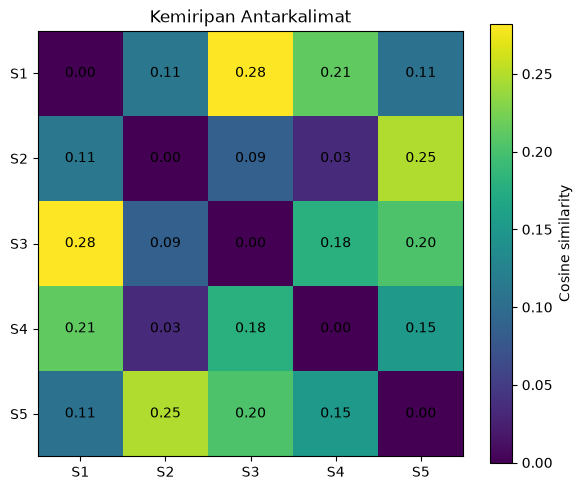

In [48]:
plt.figure(figsize=(6, 5))
plt.imshow(similarity)
plt.xticks(range(len(dokumen)), [f"S{i}" for i in range(1, len(dokumen)+1)])
plt.yticks(range(len(dokumen)), [f"S{i}" for i in range(1, len(dokumen)+1)])
plt.colorbar(label="Cosine similarity")
plt.title("Kemiripan Antarkalimat")
for i in range(len(dokumen)):
    for j in range(len(dokumen)):
        plt.text(j, i, f"{similarity[i,j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()


In [49]:
#MEMBENTUK MATRIKS TRANSISI

In [50]:
jumlah_bobot_keluar = similarity.sum(axis=1)

transition = np.zeros_like(similarity)
for j in range(len(dokumen)):
    if jumlah_bobot_keluar[j] > 0:
        transition[j, :] = similarity[j, :] / jumlah_bobot_keluar[j]

transition_df = pd.DataFrame(
    transition,
    index=[f"Dari S{i}" for i in range(1, len(dokumen)+1)],
    columns=[f"Ke S{i}" for i in range(1, len(dokumen)+1)]
)

print("Jumlah bobot keluar per kalimat:")
display(pd.Series(jumlah_bobot_keluar, index=[f"S{i}" for i in range(1, len(dokumen)+1)]).round(3))

print("\nMatriks transisi:")
display(transition_df.round(3))

print("\nCek jumlah setiap baris:")
display(pd.Series(transition.sum(axis=1), index=transition_df.index).round(3))


Jumlah bobot keluar per kalimat:


S1    0.714
S2    0.480
S3    0.750
S4    0.579
S5    0.710
dtype: float64


Matriks transisi:


,Ke S1,Ke S2,Ke S3,Ke S4,Ke S5
Dari S1,0.000,0.157,0.395,0.299,0.149
Dari S2,0.234,0.000,0.179,0.072,0.516
Dari S3,0.376,0.115,0.000,0.238,0.271
Dari S4,0.369,0.060,0.308,0.000,0.263
Dari S5,0.150,0.349,0.286,0.215,0.000



Cek jumlah setiap baris:


Dari S1    1.0
Dari S2    1.0
Dari S3    1.0
Dari S4    1.0
Dari S5    1.0
dtype: float64

In [51]:
#MENGHITUNG TEXTRANK SECARA ITERATIF

In [52]:
damping = 0.85
maks_iterasi = 50
toleransi = 1e-8

scores = np.ones(len(dokumen))
riwayat = [scores.copy()]

for iterasi in range(1, maks_iterasi + 1):
    scores_baru = (1 - damping) + damping * transition.T.dot(scores)
    riwayat.append(scores_baru.copy())

    perubahan = np.abs(scores_baru - scores).max()
    scores = scores_baru

    if perubahan < toleransi:
        print(f"Konvergen pada iterasi ke-{iterasi}")
        break

riwayat_df = pd.DataFrame(
    riwayat,
    columns=[f"S{i}" for i in range(1, len(dokumen)+1)]
)

riwayat_df.index.name = "Iterasi"
riwayat_df.head(10).round(4)


Konvergen pada iterasi ke-23


,S1,S2,S3,S4,S5
Iterasi,,,,,
0,1.0000,1.0000,1.0000,1.0000,1.0000
1,1.1084,0.7283,1.1431,0.8505,1.1697
2,1.0750,0.7995,1.1403,0.9214,1.0638
3,1.0970,0.7669,1.1327,0.8974,1.1060
4,1.0859,0.7804,1.1391,0.9072,1.0874
5,1.0913,0.7745,1.1355,0.9031,1.0956
6,1.0888,0.7771,1.1374,0.9048,1.0919
7,1.0900,0.7760,1.1365,0.9041,1.0935
8,1.0894,0.7765,1.1369,0.9044,1.0928


In [53]:
#CONTOH SUBSTIRUSIRUMUS S1 ITERASI PERTAMA

In [54]:
target = 0  # S1
kontribusi = []
for j in range(len(dokumen)):
    p = transition[j, target]
    if p > 0:
        kontribusi.append((j, p, riwayat_df.iloc[0, j]))

print("TR_1(S1) = (1 - d) + d × Σ_j P(j→S1) × TR_0(Sj)")
print(f"         = {1-damping:.2f} + {damping:.2f} × [")

bagian = []
for j, p, tr0 in kontribusi:
    bagian.append(f"({p:.4f} × {tr0:.1f})")
print("             " + " + ".join(bagian))
print("           ]")

hasil_s1_iter1 = (1-damping) + damping * sum(p * tr0 for _, p, tr0 in kontribusi)
print(f"         = {hasil_s1_iter1:.4f}")


TR_1(S1) = (1 - d) + d × Σ_j P(j→S1) × TR_0(Sj)
         = 0.15 + 0.85 × [
             (0.2335 × 1.0) + (0.3758 × 1.0) + (0.3685 × 1.0) + (0.1497 × 1.0)
           ]
         = 1.1084


In [55]:
#SKOR AKHIR DAN RANKING KALIMAT

In [56]:
hasil = pd.DataFrame({
    "Kalimat": [f"S{i}" for i in range(1, len(dokumen)+1)],
    "TextRank": scores,
    "Teks": dokumen
}).sort_values("TextRank", ascending=False).reset_index(drop=True)

hasil["Peringkat"] = np.arange(1, len(hasil)+1)
hasil = hasil[["Peringkat", "Kalimat", "TextRank", "Teks"]]

hasil["TextRank"] = hasil["TextRank"].round(4)
hasil


,Peringkat,Kalimat,TextRank,Teks
0,1,S3,1.1368,Unit Sistem Informasi akan melakukan reset lay...
1,2,S5,1.0930,Evaluasi hasil perbaikan dijadwalkan pada 16 N...
2,3,S1,1.0896,Rapat koordinasi layanan akademik dilaksanakan...
3,4,S4,0.9043,Biro Akademik akan mengirim pemberitahuan kepa...
4,5,S2,0.7763,Helpdesk mencatat 128 keluhan login pada perio...


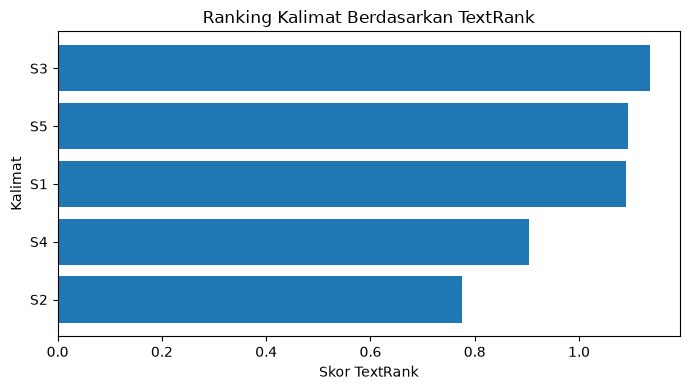

In [57]:
plt.figure(figsize=(7,4))
urutan_plot = hasil.sort_values("TextRank", ascending=True)
plt.barh(urutan_plot["Kalimat"], urutan_plot["TextRank"])
plt.xlabel("Skor TextRank")
plt.ylabel("Kalimat")
plt.title("Ranking Kalimat Berdasarkan TextRank")
plt.tight_layout()
plt.show()


In [58]:
#MEMBENTUK RINGKASAN EXTRACTIVE

In [59]:
top_n = 2

indeks_terpilih = (
    pd.DataFrame({"index": np.arange(len(dokumen)), "score": scores})
    .sort_values("score", ascending=False)
    .head(top_n)["index"]
    .sort_values()
    .tolist()
)

ringkasan = " ".join(dokumen[i] for i in indeks_terpilih)

print("Kalimat terpilih:", [f"S{i+1}" for i in indeks_terpilih])
print("\nRINGKASAN TEXTRANK:")
print(ringkasan)


Kalimat terpilih: ['S3', 'S5']

RINGKASAN TEXTRANK:
Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00. Evaluasi hasil perbaikan dijadwalkan pada 16 November 2026 pukul 10.00 dan akan membahas jumlah keluhan baru serta waktu respons server.


In [60]:
#PERCOBAAN
top_n = 3

indeks_terpilih = (
    pd.DataFrame({"index": np.arange(len(dokumen)), "score": scores})
    .sort_values("score", ascending=False)
    .head(top_n)["index"]
    .sort_values()
    .tolist()
)

ringkasan = " ".join(dokumen[i] for i in indeks_terpilih)

print("Kalimat terpilih:", [f"S{i+1}" for i in indeks_terpilih])
print("\nRINGKASAN TEXTRANK:")
print(ringkasan)


Kalimat terpilih: ['S1', 'S3', 'S5']

RINGKASAN TEXTRANK:
Rapat koordinasi layanan akademik dilaksanakan pada 10 November 2026 pukul 09.00-09.45 oleh Biro Akademik, Unit Sistem Informasi, dan Helpdesk Kampus. Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00. Evaluasi hasil perbaikan dijadwalkan pada 16 November 2026 pukul 10.00 dan akan membahas jumlah keluhan baru serta waktu respons server.


In [61]:
#AUDIT FAKTA

In [62]:
fakta = {
    "Entitas rapat": ["biro akademik", "unit sistem informasi", "helpdesk kampus"],
    "128 keluhan": ["128 keluhan"],
    "Respons 4,8 detik": ["4,8 detik"],
    "Reset 13 Nov 12.00": ["13 november 2026 pukul 12.00"],
    "Perbaikan 14 Nov 18.00": ["14 november 2026 pukul 18.00"],
    "Pemberitahuan LMS 13 Nov 10.00": ["13 november 2026 pukul 10.00"],
    "Evaluasi 16 Nov 10.00": ["16 november 2026 pukul 10.00"]
}

audit = []
ringkasan_lower = ringkasan.lower()

for nama, pola_list in fakta.items():
    ditemukan = any(p.lower() in ringkasan_lower for p in pola_list)
    audit.append([nama, "Ya" if ditemukan else "Tidak"])

audit_df = pd.DataFrame(audit, columns=["Fakta", "Ada dalam ringkasan TextRank?"])
audit_df


,Fakta,Ada dalam ringkasan TextRank?
0,Entitas rapat,Ya
1,128 keluhan,Tidak
2,"Respons 4,8 detik",Tidak
3,Reset 13 Nov 12.00,Ya
4,Perbaikan 14 Nov 18.00,Ya
5,Pemberitahuan LMS 13 Nov 10.00,Tidak
6,Evaluasi 16 Nov 10.00,Ya


In [63]:
#BOW
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

def normalisasi(teks):
    teks = teks.lower()
    teks = teks.replace(",", ".")  # agar 4,8 dan tanda baca tidak terlalu mengganggu tokenisasi
    teks = re.sub(r"[^a-z0-9\-\.\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

dokumen_bersih = [normalisasi(k) for k in dokumen]

vectorizer_bow = CountVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b[a-z0-9][a-z0-9\-\.]*\b"
)

X_bow = vectorizer_bow.fit_transform(dokumen_bersih)

print("Ukuran matriks BOW:", X_bow.shape)
print("Jumlah vocabulary:", len(vectorizer_bow.get_feature_names_out()))


Ukuran matriks BOW: (5, 65)
Jumlah vocabulary: 65


In [64]:
similarity_bow = cosine_similarity(X_bow)
np.fill_diagonal(similarity_bow, 0.0)

# 4. Matriks Transisi
row_sum_bow = similarity_bow.sum(axis=1)
P_bow = np.zeros_like(similarity_bow)
for i in range(len(dokumen)):
    if row_sum_bow[i] > 0:
        P_bow[i] = similarity_bow[i] / row_sum_bow[i]

# 5. Iterasi TextRank
d = 0.85
tr_bow = np.ones(len(dokumen))
for _ in range(100):
    tr_new = (1-d) + d * P_bow.T.dot(tr_bow)
    if np.max(np.abs(tr_new - tr_bow)) < 1e-8:
        tr_bow = tr_new
        break
    tr_bow = tr_new

# 6. Tampilkan Hasil
hasil_bow = pd.DataFrame({
    "Kalimat": [f"S{i}" for i in range(1, len(dokumen)+1)],
    "TextRank (BoW)": tr_bow,
    "Teks": dokumen
}).sort_values("TextRank (BoW)", ascending=False).reset_index(drop=True)

hasil_bow["TextRank (BoW)"] = hasil_bow["TextRank (BoW)"].round(4)
display(hasil_bow)


,Kalimat,TextRank (BoW),Teks
0,S3,1.1604,Unit Sistem Informasi akan melakukan reset lay...
1,S5,1.0764,Evaluasi hasil perbaikan dijadwalkan pada 16 N...
2,S1,1.0318,Rapat koordinasi layanan akademik dilaksanakan...
3,S4,0.9181,Biro Akademik akan mengirim pemberitahuan kepa...
4,S2,0.8134,Helpdesk mencatat 128 keluhan login pada perio...


In [65]:
#Angka dihapus

In [66]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

def normalisasi(teks):
    teks = teks.lower()
    teks = teks.replace(",", ".")  # agar 4,8 dan tanda baca tidak terlalu mengganggu tokenisasi
    teks = re.sub(r"\d+", "", teks)
    teks = re.sub(r"[^a-z0-9\-\.\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

dokumen_bersih = [normalisasi(k) for k in dokumen]

vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b[a-z0-9][a-z0-9\-\.]*\b"
)

X = vectorizer.fit_transform(dokumen_bersih)

print("Ukuran matriks TF-IDF:", X.shape)
print("Jumlah vocabulary:", len(vectorizer.get_feature_names_out()))

Ukuran matriks TF-IDF: (5, 53)
Jumlah vocabulary: 53


In [67]:
fitur = vectorizer.get_feature_names_out()
tfidf = pd.DataFrame(X.toarray(), index=[f"S{i}" for i in range(1, len(dokumen)+1)], columns=fitur)

fitur_penting = (
    tfidf.max(axis=0)
    .sort_values(ascending=False)
    .head(18)
    .index
)

tfidf[fitur_penting].round(3)

,akademik,kepada,melalui,mahasiswa,lms,mengirim,sebelum,pemberitahuan,pada,jumlah,baru,dijadwalkan,serta,membahas,evaluasi,hasil,pukul,sibuk
S1,0.451,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.157,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.157,0.00
S2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.316,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.28
S3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.142,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.285,0.00
S4,0.265,0.328,0.328,0.328,0.328,0.328,0.328,0.328,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.185,0.00
S5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.163,0.289,0.289,0.289,0.289,0.289,0.289,0.289,0.163,0.00


In [68]:
similarity = cosine_similarity(X)
np.fill_diagonal(similarity, 0.0)

sim_df = pd.DataFrame(
    similarity,
    index=[f"S{i}" for i in range(1, len(dokumen)+1)],
    columns=[f"S{i}" for i in range(1, len(dokumen)+1)]
)

sim_df.round(3)

,S1,S2,S3,S4,S5
S1,0.000,0.118,0.315,0.229,0.106
S2,0.118,0.000,0.077,0.021,0.280
S3,0.315,0.077,0.000,0.127,0.215
S4,0.229,0.021,0.127,0.000,0.094
S5,0.106,0.280,0.215,0.094,0.000


In [69]:
jumlah_bobot_keluar = similarity.sum(axis=1)

transition = np.zeros_like(similarity)
for j in range(len(dokumen)):
    if jumlah_bobot_keluar[j] > 0:
        transition[j, :] = similarity[j, :] / jumlah_bobot_keluar[j]

transition_df = pd.DataFrame(
    transition,
    index=[f"Dari S{i}" for i in range(1, len(dokumen)+1)],
    columns=[f"Ke S{i}" for i in range(1, len(dokumen)+1)]
)

print("Jumlah bobot keluar per kalimat:")
display(pd.Series(jumlah_bobot_keluar, index=[f"S{i}" for i in range(1, len(dokumen)+1)]).round(3))

print("\nMatriks transisi:")
display(transition_df.round(3))

print("\nCek jumlah setiap baris:")
display(pd.Series(transition.sum(axis=1), index=transition_df.index).round(3))


Jumlah bobot keluar per kalimat:


S1    0.767
S2    0.496
S3    0.735
S4    0.471
S5    0.695
dtype: float64


Matriks transisi:


,Ke S1,Ke S2,Ke S3,Ke S4,Ke S5
Dari S1,0.000,0.154,0.410,0.298,0.138
Dari S2,0.238,0.000,0.155,0.042,0.564
Dari S3,0.428,0.105,0.000,0.173,0.293
Dari S4,0.486,0.044,0.271,0.000,0.199
Dari S5,0.152,0.403,0.310,0.135,0.000



Cek jumlah setiap baris:


Dari S1    1.0
Dari S2    1.0
Dari S3    1.0
Dari S4    1.0
Dari S5    1.0
dtype: float64

In [70]:
damping = 0.85
maks_iterasi = 50
toleransi = 1e-8

scores = np.ones(len(dokumen))
riwayat = [scores.copy()]

for iterasi in range(1, maks_iterasi + 1):
    scores_baru = (1 - damping) + damping * transition.T.dot(scores)
    riwayat.append(scores_baru.copy())

    perubahan = np.abs(scores_baru - scores).max()
    scores = scores_baru

    if perubahan < toleransi:
        print(f"Konvergen pada iterasi ke-{iterasi}")
        break

riwayat_df = pd.DataFrame(
    riwayat,
    columns=[f"S{i}" for i in range(1, len(dokumen)+1)]
)

riwayat_df.index.name = "Iterasi"
riwayat_df.head(10).round(4)

Konvergen pada iterasi ke-27


,S1,S2,S3,S4,S5
Iterasi,,,,,
0,1.0000,1.0000,1.0000,1.0000,1.0000
1,1.2587,0.7503,1.1242,0.7015,1.1653
2,1.1515,0.8406,1.1564,0.7954,1.0562
3,1.2061,0.7956,1.1237,0.7637,1.1109
4,1.1791,0.8174,1.1440,0.7774,1.0822
5,1.1928,0.8063,1.1330,0.7710,1.0968
6,1.1859,0.8119,1.1387,0.7741,1.0893
7,1.1894,0.8091,1.1358,0.7726,1.0931
8,1.1876,0.8105,1.1373,0.7734,1.0912


In [71]:
hasil = pd.DataFrame({
    "Kalimat": [f"S{i}" for i in range(1, len(dokumen)+1)],
    "TextRank": scores,
    "Teks": dokumen
}).sort_values("TextRank", ascending=False).reset_index(drop=True)

hasil["Peringkat"] = np.arange(1, len(hasil)+1)
hasil = hasil[["Peringkat", "Kalimat", "TextRank", "Teks"]]

hasil["TextRank"] = hasil["TextRank"].round(4)
hasil


,Peringkat,Kalimat,TextRank,Teks
0,1,S1,1.1882,Rapat koordinasi layanan akademik dilaksanakan...
1,2,S3,1.1368,Unit Sistem Informasi akan melakukan reset lay...
2,3,S5,1.0919,Evaluasi hasil perbaikan dijadwalkan pada 16 N...
3,4,S2,0.8100,Helpdesk mencatat 128 keluhan login pada perio...
4,5,S4,0.7731,Biro Akademik akan mengirim pemberitahuan kepa...


In [72]:
top_n = 2

indeks_terpilih = (
    pd.DataFrame({"index": np.arange(len(dokumen)), "score": scores})
    .sort_values("score", ascending=False)
    .head(top_n)["index"]
    .sort_values()
    .tolist()
)

ringkasan = " ".join(dokumen[i] for i in indeks_terpilih)

print("Kalimat terpilih:", [f"S{i+1}" for i in indeks_terpilih])
print("\nRINGKASAN TEXTRANK:")
print(ringkasan)


Kalimat terpilih: ['S1', 'S3']

RINGKASAN TEXTRANK:
Rapat koordinasi layanan akademik dilaksanakan pada 10 November 2026 pukul 09.00-09.45 oleh Biro Akademik, Unit Sistem Informasi, dan Helpdesk Kampus. Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00.


In [73]:
dokumen = [
    "Rapat koordinasi layanan akademik dilaksanakan pada 10 November 2026 pukul 09.00-09.45 oleh Biro Akademik, Unit Sistem Informasi, dan Helpdesk Kampus.",
    "Helpdesk mencatat 128 keluhan login pada periode 3-9 November 2026, sedangkan waktu respons server pada jam sibuk mencapai 4,8 detik.",
    "Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00.",
    "Biro Akademik akan mengirim pemberitahuan kepada mahasiswa melalui LMS sebelum 13 November 2026 pukul 10.00.",
    "Evaluasi hasil perbaikan dijadwalkan pada 16 November 2026 pukul 10.00 dan akan membahas jumlah keluhan baru serta waktu respons server.",
     "Helpdesk melaporkan adanya 130 keluhan terkait login selama periode 4-10 November 2026, dan waktu respons server melambat hingga 5 detik pada jam sibuk."
]

for i, kalimat in enumerate(dokumen, start=1):
    print(f"S{i}: {kalimat}")


S1: Rapat koordinasi layanan akademik dilaksanakan pada 10 November 2026 pukul 09.00-09.45 oleh Biro Akademik, Unit Sistem Informasi, dan Helpdesk Kampus.
S2: Helpdesk mencatat 128 keluhan login pada periode 3-9 November 2026, sedangkan waktu respons server pada jam sibuk mencapai 4,8 detik.
S3: Unit Sistem Informasi akan melakukan reset layanan autentikasi paling lambat 13 November 2026 pukul 12.00 dan menjadwalkan pemasangan perbaikan perangkat lunak pada 14 November 2026 pukul 18.00.
S4: Biro Akademik akan mengirim pemberitahuan kepada mahasiswa melalui LMS sebelum 13 November 2026 pukul 10.00.
S5: Evaluasi hasil perbaikan dijadwalkan pada 16 November 2026 pukul 10.00 dan akan membahas jumlah keluhan baru serta waktu respons server.
S6: Helpdesk melaporkan adanya 130 keluhan terkait login selama periode 4-10 November 2026, dan waktu respons server melambat hingga 5 detik pada jam sibuk.


In [74]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

def normalisasi(teks):
    teks = teks.lower()
    teks = teks.replace(",", ".")  # agar 4,8 dan tanda baca tidak terlalu mengganggu tokenisasi
    teks = re.sub(r"[^a-z0-9\-\.\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

dokumen_bersih = [normalisasi(k) for k in dokumen]

vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b[a-z0-9][a-z0-9\-\.]*\b"
)

X = vectorizer.fit_transform(dokumen_bersih)

print("Ukuran matriks TF-IDF:", X.shape)
print("Jumlah vocabulary:", len(vectorizer.get_feature_names_out()))


Ukuran matriks TF-IDF: (6, 74)
Jumlah vocabulary: 74


In [75]:
fitur = vectorizer.get_feature_names_out()
tfidf = pd.DataFrame(X.toarray(), index=[f"S{i}" for i in range(1, len(dokumen)+1)], columns=fitur)

fitur_penting = (
    tfidf.max(axis=0)
    .sort_values(ascending=False)
    .head(18)
    .index
)

tfidf[fitur_penting].round(3)


,akademik,kepada,melalui,mengirim,pemberitahuan,sebelum,lms,mahasiswa,pada,16,hasil,jumlah,membahas,serta,dijadwalkan,evaluasi,baru,mencapai
S1,0.425,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.133,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
S2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.282,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.275
S3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.114,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
S4,0.248,0.303,0.303,0.303,0.303,0.303,0.303,0.303,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
S5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.142,0.276,0.276,0.276,0.276,0.276,0.276,0.276,0.276,0.000
S6,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.129,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [76]:
similarity = cosine_similarity(X)
np.fill_diagonal(similarity, 0.0)

sim_df = pd.DataFrame(
    similarity,
    index=[f"S{i}" for i in range(1, len(dokumen)+1)],
    columns=[f"S{i}" for i in range(1, len(dokumen)+1)]
)

sim_df.round(3)


,S1,S2,S3,S4,S5,S6
S1,0.000,0.100,0.277,0.217,0.097,0.097
S2,0.100,0.000,0.081,0.033,0.216,0.463
S3,0.277,0.081,0.000,0.178,0.201,0.079
S4,0.217,0.033,0.178,0.000,0.159,0.030
S5,0.097,0.216,0.201,0.159,0.000,0.204
S6,0.097,0.463,0.079,0.030,0.204,0.000


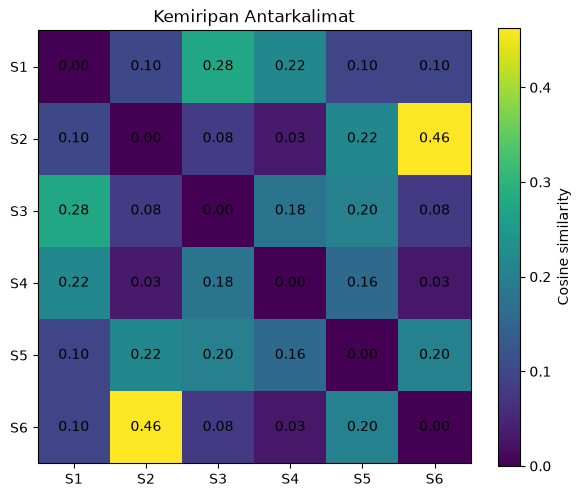

In [77]:
plt.figure(figsize=(6, 5))
plt.imshow(similarity)
plt.xticks(range(len(dokumen)), [f"S{i}" for i in range(1, len(dokumen)+1)])
plt.yticks(range(len(dokumen)), [f"S{i}" for i in range(1, len(dokumen)+1)])
plt.colorbar(label="Cosine similarity")
plt.title("Kemiripan Antarkalimat")
for i in range(len(dokumen)):
    for j in range(len(dokumen)):
        plt.text(j, i, f"{similarity[i,j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()


In [78]:
jumlah_bobot_keluar = similarity.sum(axis=1)

transition = np.zeros_like(similarity)
for j in range(len(dokumen)):
    if jumlah_bobot_keluar[j] > 0:
        transition[j, :] = similarity[j, :] / jumlah_bobot_keluar[j]

transition_df = pd.DataFrame(
    transition,
    index=[f"Dari S{i}" for i in range(1, len(dokumen)+1)],
    columns=[f"Ke S{i}" for i in range(1, len(dokumen)+1)]
)

print("Jumlah bobot keluar per kalimat:")
display(pd.Series(jumlah_bobot_keluar, index=[f"S{i}" for i in range(1, len(dokumen)+1)]).round(3))

print("\nMatriks transisi:")
display(transition_df.round(3))

print("\nCek jumlah setiap baris:")
display(pd.Series(transition.sum(axis=1), index=transition_df.index).round(3))


Jumlah bobot keluar per kalimat:


S1    0.788
S2    0.892
S3    0.816
S4    0.617
S5    0.876
S6    0.872
dtype: float64


Matriks transisi:


,Ke S1,Ke S2,Ke S3,Ke S4,Ke S5,Ke S6
Dari S1,0.000,0.127,0.352,0.275,0.124,0.123
Dari S2,0.112,0.000,0.090,0.037,0.242,0.519
Dari S3,0.340,0.099,0.000,0.219,0.246,0.097
Dari S4,0.351,0.053,0.289,0.000,0.257,0.049
Dari S5,0.111,0.246,0.229,0.181,0.000,0.232
Dari S6,0.111,0.531,0.090,0.034,0.233,0.000



Cek jumlah setiap baris:


Dari S1    1.0
Dari S2    1.0
Dari S3    1.0
Dari S4    1.0
Dari S5    1.0
Dari S6    1.0
dtype: float64

In [79]:
damping = 0.85
maks_iterasi = 50
toleransi = 1e-8

scores = np.ones(len(dokumen))
riwayat = [scores.copy()]

for iterasi in range(1, maks_iterasi + 1):
    scores_baru = (1 - damping) + damping * transition.T.dot(scores)
    riwayat.append(scores_baru.copy())

    perubahan = np.abs(scores_baru - scores).max()
    scores = scores_baru

    if perubahan < toleransi:
        print(f"Konvergen pada iterasi ke-{iterasi}")
        break

riwayat_df = pd.DataFrame(
    riwayat,
    columns=[f"S{i}" for i in range(1, len(dokumen)+1)]
)

riwayat_df.index.name = "Iterasi"
riwayat_df.head(10).round(4)


Konvergen pada iterasi ke-19


,S1,S2,S3,S4,S5,S6
Iterasi,,,,,,
0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,1.0217,1.0470,1.0432,0.7843,1.0869,1.0169
2,0.9840,1.0690,1.0184,0.8127,1.0640,1.0517
3,0.9886,1.0751,1.0141,0.7975,1.0726,1.0521
4,0.9842,1.0765,1.0139,0.7993,1.0701,1.0560
5,0.9850,1.0773,1.0129,0.7980,1.0711,1.0557
6,0.9845,1.0774,1.0130,0.7982,1.0708,1.0562
7,0.9846,1.0775,1.0129,0.7980,1.0709,1.0561
8,0.9845,1.0775,1.0129,0.7980,1.0708,1.0562


In [80]:
hasil = pd.DataFrame({
    "Kalimat": [f"S{i}" for i in range(1, len(dokumen)+1)],
    "TextRank": scores,
    "Teks": dokumen
}).sort_values("TextRank", ascending=False).reset_index(drop=True)

hasil["Peringkat"] = np.arange(1, len(hasil)+1)
hasil = hasil[["Peringkat", "Kalimat", "TextRank", "Teks"]]

hasil["TextRank"] = hasil["TextRank"].round(4)
hasil


,Peringkat,Kalimat,TextRank,Teks
0,1,S2,1.0775,Helpdesk mencatat 128 keluhan login pada perio...
1,2,S5,1.0709,Evaluasi hasil perbaikan dijadwalkan pada 16 N...
2,3,S6,1.0562,Helpdesk melaporkan adanya 130 keluhan terkait...
3,4,S3,1.0129,Unit Sistem Informasi akan melakukan reset lay...
4,5,S1,0.9845,Rapat koordinasi layanan akademik dilaksanakan...
5,6,S4,0.7980,Biro Akademik akan mengirim pemberitahuan kepa...


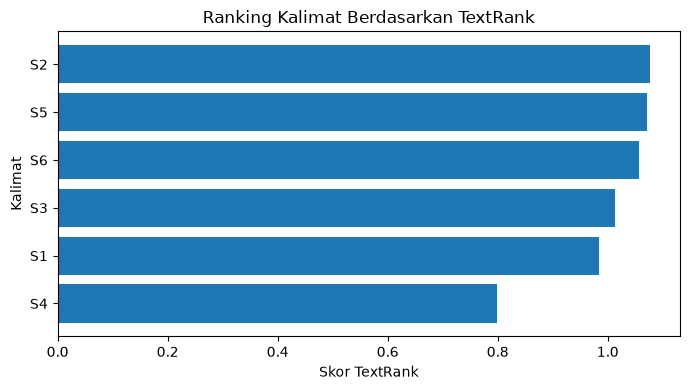

In [81]:
plt.figure(figsize=(7,4))
urutan_plot = hasil.sort_values("TextRank", ascending=True)
plt.barh(urutan_plot["Kalimat"], urutan_plot["TextRank"])
plt.xlabel("Skor TextRank")
plt.ylabel("Kalimat")
plt.title("Ranking Kalimat Berdasarkan TextRank")
plt.tight_layout()
plt.show()
